# Lab Assignment 2: Nearest-Track Search Benchmark (Exact NN vs. ANNOY vs. FAISS vs. HNSW)
## Dataset: Micro Spotify (`bwandowando/spotify-songs-with-attributes-and-lyrics`)

### Objectives
1. Download and load the first CSV dataset from the **Spotify Songs with Attributes and Lyrics** Kaggle repository.
2. Extract the 9 numerical audio features and normalize them using `StandardScaler`.
3. Build search indices and perform Top-$k$ ($k=10$) nearest-track searches using:
   - **Exact Nearest Neighbors** (`sklearn.neighbors.NearestNeighbors`)
   - **ANNOY** (`annoy.AnnoyIndex`)
   - **FAISS** (`faiss.IndexIVFFlat`)
   - **HNSW** (`hnswlib.Index`)
4. Compare all four approaches in terms of **Index Build Time**, **Query Latency**, **Speedup over Exact NN**, **Recall@10**, and **Qualitative Track Recommendations**.

In [1]:
!pip install -q kagglehub annoy faiss-cpu hnswlib scikit-learn pandas numpy matplotlib

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [2]:
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import kagglehub
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Reproducibility & Benchmark Settings
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

K = 10               # Number of nearest neighbors (top-k tracks)
NUM_QUERIES = 100    # Number of query tracks for latency & recall evaluation

# ANN Hyperparameters
ANNOY_TREES = 10
FAISS_NLIST = 256
FAISS_NPROBE = 10
HNSW_M = 16
HNSW_EF_CONSTRUCTION = 100
HNSW_EF_SEARCH = 50

In [3]:
# Download dataset from Kaggle (or point DATA_DIR to your local folder if already downloaded)
dataset_path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")
print("Dataset directory:", dataset_path)

# List all CSV files and select the first dataset
csv_files = sorted(glob.glob(os.path.join(dataset_path, "*.csv")))
print("Available CSV files:", [os.path.basename(f) for f in csv_files])

first_csv_path = csv_files[0]
print(f"\nLoading first dataset: {os.path.basename(first_csv_path)}")
df = pd.read_csv(first_csv_path)

print(f"Dataset shape: {df.shape}")
df.head(3)

100%|██████████| 894M/894M [01:24<00:00, 11.1MB/s] 

Extracting files...


Dataset directory: C:\Users\andhi\.cache\kagglehub\datasets\bwandowando\spotify-songs-with-attributes-and-lyrics\versions\20
Available CSV files: ['songs_with_attributes_and_lyrics.csv', 'songs_with_lyrics_and_timestamps.csv']

Loading first dataset: songs_with_attributes_and_lyrics.csv
Dataset shape: (955320, 17)


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838,0.471,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000,0.176,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000,0.479,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"


In [6]:
features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

# Drop rows with missing values in the selected audio features
df_clean = df.dropna(subset=features).reset_index(drop=True)
print(f"Total valid tracks after dropping NaNs: {len(df_clean):,}")

# Extract numerical features
X = df_clean[features].values

# Feature standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert to contiguous float32 array (required by FAISS and HNSWLIB)
X_scaled = np.ascontiguousarray(X_scaled, dtype=np.float32)
n_samples, dim = X_scaled.shape
print(f"Normalized feature matrix shape: {X_scaled.shape} | dtype: {X_scaled.dtype}")

# Sample query track indices (including index 0 for qualitative inspection)
rng = np.random.default_rng(RANDOM_SEED)
random_query_ids = rng.choice(np.arange(1, n_samples), size=NUM_QUERIES - 1, replace=False)
query_ids = np.concatenate(([0], random_query_ids))
query_vectors = np.ascontiguousarray(X_scaled[query_ids], dtype=np.float32)

# Detect track title and artist columns automatically for readable output
title_col = next((c for c in ['name', 'track_name', 'song_name'] if c in df_clean.columns), None)
artist_col = next((c for c in ['artists', 'artist_name', 'track_artist'] if c in df_clean.columns), None)
print(f"Detected metadata columns -> Title: '{title_col}', Artist: '{artist_col}'")

Total valid tracks after dropping NaNs: 955,320
Normalized feature matrix shape: (955320, 9) | dtype: float32
Detected metadata columns -> Title: 'name', Artist: 'artists'


In [7]:
print("Building Exact NN (Brute-Force Euclidean)...")
t0 = time.perf_counter()
exact_nn = NearestNeighbors(n_neighbors=K + 1, metric='euclidean', algorithm='brute', n_jobs=-1)
exact_nn.fit(X_scaled)
exact_build_time = time.perf_counter() - t0

# Query Exact NN (retrieve K+1 and exclude self-match at position 0)
t0 = time.perf_counter()
exact_dists_raw, exact_indices_raw = exact_nn.kneighbors(query_vectors)
exact_query_time = time.perf_counter() - t0

# Exclude the query track itself from its neighbor list
exact_indices = exact_indices_raw[:, 1:K+1]
exact_dists = exact_dists_raw[:, 1:K+1]
exact_avg_query_ms = (exact_query_time / NUM_QUERIES) * 1000.0

print(f"Exact NN -> Build Time: {exact_build_time:.4f}s | Avg Query Time: {exact_avg_query_ms:.4f} ms/query")

Building Exact NN (Brute-Force Euclidean)...
Exact NN -> Build Time: 0.0038s | Avg Query Time: 1.7533 ms/query


In [8]:
print("Building ANNOY Index...")
t0 = time.perf_counter()
annoy_index = AnnoyIndex(dim, metric='euclidean')
for i in range(n_samples):
    annoy_index.add_item(i, X_scaled[i])
annoy_index.build(ANNOY_TREES)
annoy_build_time = time.perf_counter() - t0

# Query ANNOY
annoy_indices = np.empty((NUM_QUERIES, K), dtype=np.int64)
annoy_dists = np.empty((NUM_QUERIES, K), dtype=np.float32)

t0 = time.perf_counter()
for i, q_vec in enumerate(query_vectors):
    idxs, dists = annoy_index.get_nns_by_vector(q_vec, K + 1, include_distances=True)
    # Remove self-match if present
    filtered = [(idx, d) for idx, d in zip(idxs, dists) if idx != query_ids[i]][:K]
    annoy_indices[i] = [x[0] for x in filtered]
    annoy_dists[i] = [x[1] for x in filtered]
annoy_query_time = time.perf_counter() - t0
annoy_avg_query_ms = (annoy_query_time / NUM_QUERIES) * 1000.0

print(f"ANNOY    -> Build Time: {annoy_build_time:.4f}s | Avg Query Time: {annoy_avg_query_ms:.4f} ms/query")

Building ANNOY Index...
ANNOY    -> Build Time: 2.5111s | Avg Query Time: 0.0471 ms/query


In [10]:
print("Building FAISS Index (IndexIVFFlat - L2)...")
nlist = min(FAISS_NLIST, max(1, n_samples // 39))

t0 = time.perf_counter()
quantizer = faiss.IndexFlatL2(dim)
faiss_index = faiss.IndexIVFFlat(quantizer, dim, nlist, faiss.METRIC_L2)
faiss_index.train(X_scaled)
faiss_index.add(X_scaled)
faiss_build_time = time.perf_counter() - t0

# Query FAISS
faiss_index.nprobe = min(FAISS_NPROBE, nlist)
t0 = time.perf_counter()
faiss_dists_sq, faiss_indices_raw = faiss_index.search(query_vectors, K + 1)
faiss_query_time = time.perf_counter() - t0
faiss_avg_query_ms = (faiss_query_time / NUM_QUERIES) * 1000.0

# Filter out self-match and convert squared L2 distance to Euclidean distance
faiss_indices = np.empty((NUM_QUERIES, K), dtype=np.int64)
faiss_dists = np.empty((NUM_QUERIES, K), dtype=np.float32)

for i in range(NUM_QUERIES):
    filtered = [
        (idx, np.sqrt(max(d2, 0.0)))
        for idx, d2 in zip(faiss_indices_raw[i], faiss_dists_sq[i])
        if idx != query_ids[i] and idx != -1
    ][:K]
    faiss_indices[i] = [x[0] for x in filtered]
    faiss_dists[i] = [x[1] for x in filtered]

print(f"FAISS    -> Build Time: {faiss_build_time:.4f}s | Avg Query Time: {faiss_avg_query_ms:.4f} ms/query")

Building FAISS Index (IndexIVFFlat - L2)...
FAISS    -> Build Time: 0.6332s | Avg Query Time: 0.0379 ms/query


In [11]:
print("Building HNSWLIB Index (L2)...")
t0 = time.perf_counter()
hnsw_index = hnswlib.Index(space='l2', dim=dim)
hnsw_index.init_index(max_elements=n_samples, ef_construction=HNSW_EF_CONSTRUCTION, M=HNSW_M)
hnsw_index.add_items(X_scaled, np.arange(n_samples))
hnsw_build_time = time.perf_counter() - t0

# Query HNSWLIB
hnsw_index.set_ef(HNSW_EF_SEARCH)
t0 = time.perf_counter()
hnsw_indices_raw, hnsw_dists_sq = hnsw_index.knn_query(query_vectors, k=K + 1)
hnsw_query_time = time.perf_counter() - t0
hnsw_avg_query_ms = (hnsw_query_time / NUM_QUERIES) * 1000.0

# Filter out self-match and convert squared L2 distance to Euclidean distance
hnsw_indices = np.empty((NUM_QUERIES, K), dtype=np.int64)
hnsw_dists = np.empty((NUM_QUERIES, K), dtype=np.float32)

for i in range(NUM_QUERIES):
    filtered = [
        (idx, np.sqrt(max(d2, 0.0)))
        for idx, d2 in zip(hnsw_indices_raw[i], hnsw_dists_sq[i])
        if idx != query_ids[i]
    ][:K]
    hnsw_indices[i] = [x[0] for x in filtered]
    hnsw_dists[i] = [x[1] for x in filtered]

print(f"HNSWLIB  -> Build Time: {hnsw_build_time:.4f}s | Avg Query Time: {hnsw_avg_query_ms:.4f} ms/query")

Building HNSWLIB Index (L2)...
HNSWLIB  -> Build Time: 7.3411s | Avg Query Time: 0.0355 ms/query


In [13]:
def compute_recall_at_k(pred_indices: np.ndarray, gt_indices: np.ndarray) -> float:
    """Computes mean Recall@K (%) relative to Exact Nearest Neighbors."""
    k = gt_indices.shape[1]
    recalls = [
        len(set(pred).intersection(set(gt))) / k
        for pred, gt in zip(pred_indices, gt_indices)
    ]
    return float(np.mean(recalls) * 100.0)

summary_data = [
    {
        "Algorithm": "Exact NN (Brute-Force)",
        "Build Time (s)": round(exact_build_time, 4),
        "Total Query Time (s)": round(exact_query_time, 4),
        "Avg Query Time (ms)": round(exact_avg_query_ms, 4),
        "Speedup vs Exact NN": "1.00x",
        f"Recall@{K} (%)": 100.00
    },
    {
        "Algorithm": "ANNOY",
        "Build Time (s)": round(annoy_build_time, 4),
        "Total Query Time (s)": round(annoy_query_time, 4),
        "Avg Query Time (ms)": round(annoy_avg_query_ms, 4),
        "Speedup vs Exact NN": f"{exact_avg_query_ms / annoy_avg_query_ms:.2f}x",
        f"Recall@{K} (%)": round(compute_recall_at_k(annoy_indices, exact_indices), 2)
    },
    {
        "Algorithm": "FAISS (IVFFlat)",
        "Build Time (s)": round(faiss_build_time, 4),
        "Total Query Time (s)": round(faiss_query_time, 4),
        "Avg Query Time (ms)": round(faiss_avg_query_ms, 4),
        "Speedup vs Exact NN": f"{exact_avg_query_ms / faiss_avg_query_ms:.2f}x",
        f"Recall@{K} (%)": round(compute_recall_at_k(faiss_indices, exact_indices), 2)
    },
    {
        "Algorithm": "HNSWLIB",
        "Build Time (s)": round(hnsw_build_time, 4),
        "Total Query Time (s)": round(hnsw_query_time, 4),
        "Avg Query Time (ms)": round(hnsw_avg_query_ms, 4),
        "Speedup vs Exact NN": f"{exact_avg_query_ms / hnsw_avg_query_ms:.2f}x",
        f"Recall@{K} (%)": round(compute_recall_at_k(hnsw_indices, exact_indices), 2)
    }
]

df_benchmark = pd.DataFrame(summary_data)
display(df_benchmark)

,Algorithm,Build Time (s),Total Query Time (s),Avg Query Time (ms),Speedup vs Exact NN,Recall@10 (%)
0,Exact NN (Brute-Force),0.0038,0.1753,1.7533,1.00x,100.0
1,ANNOY,2.5111,0.0047,0.0471,37.24x,82.7
2,FAISS (IVFFlat),0.6332,0.0038,0.0379,46.23x,99.1
3,HNSWLIB,7.3411,0.0035,0.0355,49.42x,99.5


In [15]:
def format_track_label(row_idx: int) -> str:
    """Formats track title and artist for display."""
    if title_col and artist_col:
        return f"{df_clean.loc[row_idx, title_col]} — {df_clean.loc[row_idx, artist_col]} (ID:{row_idx})"
    elif title_col:
        return f"{df_clean.loc[row_idx, title_col]} (ID:{row_idx})"
    return f"Track Index {row_idx}"

# Inspect Top-10 nearest tracks for the first query song (query_ids[0] = 0)
sample_q_pos = 0
sample_track_idx = query_ids[sample_q_pos]

print("=" * 85)
print(f"QUERY TRACK: {format_track_label(sample_track_idx)}")
print("Audio Features:", dict(zip(features, np.round(df_clean.loc[sample_track_idx, features].values.astype(float), 3))))
print("=" * 85)

comparison_df = pd.DataFrame({
    "Rank": np.arange(1, K + 1),
    "Exact NN": [
        f"{format_track_label(idx)} [d={d:.3f}]"
        for idx, d in zip(exact_indices[sample_q_pos], exact_dists[sample_q_pos])
    ],
    "ANNOY": [
        f"{format_track_label(idx)} [d={d:.3f}]"
        for idx, d in zip(annoy_indices[sample_q_pos], annoy_dists[sample_q_pos])
    ],
    "FAISS": [
        f"{format_track_label(idx)} [d={d:.3f}]"
        for idx, d in zip(faiss_indices[sample_q_pos], faiss_dists[sample_q_pos])
    ],
    "HNSWLIB": [
        f"{format_track_label(idx)} [d={d:.3f}]"
        for idx, d in zip(hnsw_indices[sample_q_pos], hnsw_dists[sample_q_pos])
    ]
})

pd.set_option("display.max_colwidth", 65)
display(comparison_df)

QUERY TRACK: ! — HELLYEAH (ID:0)
Audio Features: {'danceability': np.float64(0.415), 'energy': np.float64(0.605), 'loudness': np.float64(-11.157), 'speechiness': np.float64(0.058), 'acousticness': np.float64(0.001), 'instrumentalness': np.float64(0.838), 'liveness': np.float64(0.471), 'valence': np.float64(0.193), 'tempo': np.float64(100.059)}


,Rank,Exact NN,ANNOY,FAISS,HNSWLIB
0,1,Intro (Who The Fuck Are You') — C-Lekktor (ID:394553) [d=0.887],Intro (Who The Fuck Are You') — C-Lekktor (ID:394553) [d=0.887],Intro (Who The Fuck Are You') — C-Lekktor (ID:394553) [d=0.887],Intro (Who The Fuck Are You') — C-Lekktor (ID:394553) [d=0.887]
1,2,Testimonium — Lacrimosa (ID:764272) [d=0.909],Testimonium — Lacrimosa (ID:764272) [d=0.909],Testimonium — Lacrimosa (ID:764272) [d=0.909],Testimonium — Lacrimosa (ID:764272) [d=0.909]
2,3,Ultimate Satisfaction - The Field Remix — Bear In Heaven (ID:...,Ultimate Satisfaction - The Field Remix — Bear In Heaven (ID:...,Ultimate Satisfaction - The Field Remix — Bear In Heaven (ID:...,Ultimate Satisfaction - The Field Remix — Bear In Heaven (ID:...
3,4,Sæglópur — Sigur Rós (ID:749223) [d=0.938],Autumn Interlude — Amethystium (ID:61511) [d=0.947],Sæglópur — Sigur Rós (ID:749223) [d=0.938],Sæglópur — Sigur Rós (ID:749223) [d=0.938]
4,5,Autumn Interlude — Amethystium (ID:61511) [d=0.947],Púrpura — Margaritas Podridas (ID:625227) [d=0.976],Autumn Interlude — Amethystium (ID:61511) [d=0.947],Autumn Interlude — Amethystium (ID:61511) [d=0.947]
5,6,Púrpura — Margaritas Podridas (ID:625227) [d=0.976],Turn from Heaven — Therion (ID:833164) [d=0.995],Púrpura — Margaritas Podridas (ID:625227) [d=0.976],Púrpura — Margaritas Podridas (ID:625227) [d=0.976]
6,7,Turn from Heaven — Therion (ID:833164) [d=0.995],See You When I Die — BOYO (ID:676733) [d=1.021],Turn from Heaven — Therion (ID:833164) [d=0.995],Turn from Heaven — Therion (ID:833164) [d=0.995]
7,8,See You When I Die — BOYO (ID:676733) [d=1.021],Mrityu — Multani;Karun;Udbhav (ID:523698) [d=1.041],See You When I Die — BOYO (ID:676733) [d=1.021],See You When I Die — BOYO (ID:676733) [d=1.021]
8,9,Mrityu — Multani;Karun;Udbhav (ID:523698) [d=1.041],Teri Yaadon Se - Lofi Flip — Jammy Weirdo;Mustafa Zahid;Prana...,Mrityu — Multani;Karun;Udbhav (ID:523698) [d=1.041],Mrityu — Multani;Karun;Udbhav (ID:523698) [d=1.041]
9,10,Bewitched — The Wedding Present (ID:85956) [d=1.046],Long Was The Year — Broadcast (ID:466594) [d=1.060],Bewitched — The Wedding Present (ID:85956) [d=1.046],Bewitched — The Wedding Present (ID:85956) [d=1.046]


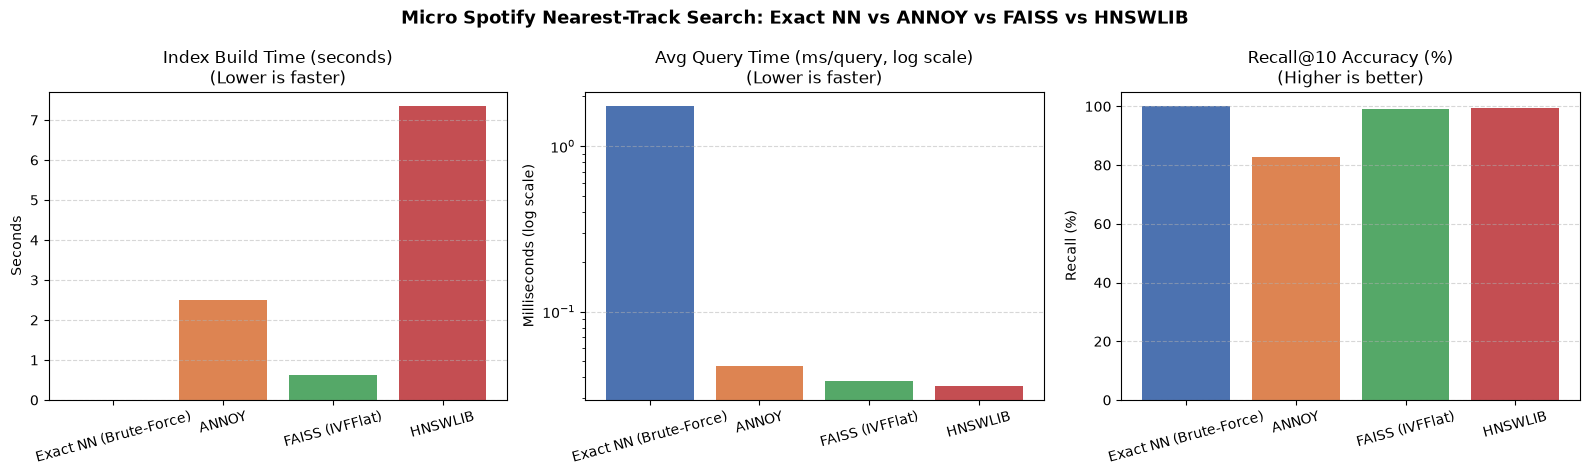

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
fig.suptitle("Micro Spotify Nearest-Track Search: Exact NN vs ANNOY vs FAISS vs HNSWLIB", fontsize=13, fontweight="bold")

colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

# 1. Index Build Time
axes[0].bar(df_benchmark["Algorithm"], df_benchmark["Build Time (s)"], color=colors)
axes[0].set_title("Index Build Time (seconds)\n(Lower is faster)")
axes[0].set_ylabel("Seconds")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# 2. Average Query Latency (Log Scale)
axes[1].bar(df_benchmark["Algorithm"], df_benchmark["Avg Query Time (ms)"], color=colors)
axes[1].set_yscale("log")
axes[1].set_title("Avg Query Time (ms/query, log scale)\n(Lower is faster)")
axes[1].set_ylabel("Milliseconds (log scale)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# 3. Recall@10
axes[2].bar(df_benchmark["Algorithm"], df_benchmark[f"Recall@{K} (%)"], color=colors)
axes[2].set_title(f"Recall@{K} Accuracy (%)\n(Higher is better)")
axes[2].set_ylabel("Recall (%)")
axes[2].set_ylim(0, 105)
axes[2].tick_params(axis="x", rotation=15)
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()